In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrow
from matplotlib import animation
import matplotlib.patheffects as pe
from IPython.display import HTML, display

pd.set_option("display.max_columns", 80); pd.set_option("display.width", 200)

DATA_DIR = Path("../data")

NULLS = ["NA", "NULL", "null", "None", ""]
SEASONS = [2023, 2024, 2025]
CHUNK = 2_000_000

def find_csv(stem):
    hits = sorted(DATA_DIR.rglob(f"{stem}.csv"))
    if not hits: raise FileNotFoundError(f"{stem}.csv not found under {DATA_DIR.resolve()}")
    return hits[0]

def pick(df, candidates, required=False):
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower: return lower[c.lower()]
    if required: raise KeyError(f"None of {candidates} in {list(df.columns)}")
    return None

players = pd.read_csv(find_csv("players"), na_values=NULLS)
games   = pd.read_csv(find_csv("games"), na_values=NULLS)
pp      = pd.read_csv(find_csv("player_play"), na_values=NULLS, low_memory=False)

NAME = pick(players, ["display_name", "player_name", "full_name", "name"])
if NAME is None and {"first_name", "last_name"} <= set(players):
    players["display_name"] = players["first_name"] + " " + players["last_name"]; NAME = "display_name"
POS  = pick(players, ["nfl_position", "position"])
TEAM = pick(pp, ["team_abbr", "club", "team"], required=True)
LUP  = pick(pp, ["lined_up_position", "position_at_snap"])
POSS = pick(pp, ["possession_team"])
HOME, AWAY = pick(games, ["home_team_abbr"]), pick(games, ["visitor_team_abbr", "away_team_abbr"])

pp = pp.merge(games[["game_id", "season", "week"] + [c for c in [HOME, AWAY, "season_type"] if c]], on="game_id", how="left")
pp = pp.merge(players[["nfl_id", NAME] + ([POS] if POS else [])], on="nfl_id", how="left")
if POSS: pp["side"] = np.where(pp[TEAM] == pp[POSS], "offense", "defense")
print("player_play:", pp.shape, "| seasons:", sorted(pp["season"].dropna().unique()))

player_play: (314197, 72) | seasons: [2023, 2024, 2025]


114,954 plays with ≥1 cohort player in player_play


,count,mean,std,min,25%,50%,75%,max
players per play,114954.0,2.73,1.56,1.0,1.0,2.0,4.0,11.0


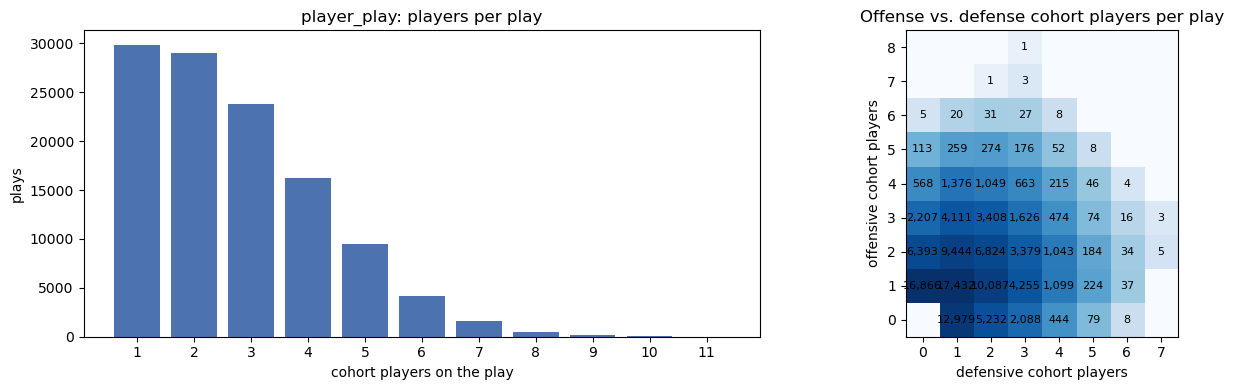

In [3]:
per_play = pp.groupby(["game_id", "play_id"]).agg(
    n_players=("nfl_id", "nunique"),
    n_off=("side", lambda s: (s == "offense").sum()) if "side" in pp else ("nfl_id", "size"),
    n_def=("side", lambda s: (s == "defense").sum()) if "side" in pp else ("nfl_id", "size"),
    season=("season", "first"))
print(f"{len(per_play):,} plays with ≥1 cohort player in player_play")
display(per_play["n_players"].describe().round(2).to_frame("players per play").T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vc = per_play["n_players"].value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color="#4C72B0")
axes[0].set_xlabel("cohort players on the play"); axes[0].set_ylabel("plays")
axes[0].set_title("player_play: players per play"); axes[0].set_xticks(vc.index)
if "side" in pp:
    ct = pd.crosstab(per_play["n_off"], per_play["n_def"])
    im = axes[1].imshow(np.log1p(ct.values), cmap="Blues", origin="lower")
    axes[1].set_xticks(range(len(ct.columns))); axes[1].set_xticklabels(ct.columns)
    axes[1].set_yticks(range(len(ct.index))); axes[1].set_yticklabels(ct.index)
    for (i, j), v in np.ndenumerate(ct.values):
        if v: axes[1].text(j, i, f"{v:,}", ha="center", va="center", fontsize=8)
    axes[1].set_xlabel("defensive cohort players"); axes[1].set_ylabel("offensive cohort players")
    axes[1].set_title("Offense vs. defense cohort players per play")
plt.tight_layout(); plt.show()

In [9]:
# Seasons each player appears in (from player_play joined to games)
seasons_per_player = (pp.groupby("nfl_id")["season"]
                        .agg(n_seasons="nunique",
                             seasons=lambda s: ",".join(map(str, sorted(s.unique())))))

# Join to all players so zero-season players are included
yrs = (players[["nfl_id", "display_name", "draft_year"]]
       .merge(seasons_per_player, on="nfl_id", how="left")
       .fillna({"n_seasons": 0, "seasons": "none"}))
yrs["n_seasons"] = yrs["n_seasons"].astype(int)
yrs["max_possible"] = 2025 - yrs["draft_year"] + 1

# Count of players by draft class × seasons represented
pd.crosstab(yrs["draft_year"], yrs["n_seasons"], margins=True)

n_seasons,0,1,2,3,All
draft_year,,,,,
2023,2,12,23,123,160
2024,2,19,156,0,177
2025,9,164,0,0,173
All,13,195,179,123,510


In [4]:
# Confirm against the tracking file itself (one season; only 3 small columns are read)
CHECK_SEASON = 2024
first = pd.read_csv(find_csv(f"game_tracking_{CHECK_SEASON}"), nrows=5)
print("tracking columns:", list(first.columns))
ball_col = pick(first, ["entity_type", "club", "display_name"])
usecols = ["game_id", "play_id", "nfl_id"] + ([ball_col] if ball_col else [])

parts, ball_rows = [], 0
for ch in pd.read_csv(find_csv(f"game_tracking_{CHECK_SEASON}"), usecols=usecols, chunksize=CHUNK, na_values=NULLS):
    is_ball = ch["nfl_id"].isna()
    if ball_col: is_ball |= ch[ball_col].astype(str).str.lower().isin(["football", "ball"])
    ball_rows += int(is_ball.sum())
    parts.append(ch.loc[~is_ball, ["game_id", "play_id", "nfl_id"]].drop_duplicates())
trk_ids = pd.concat(parts).drop_duplicates()
trk_pp = trk_ids.groupby(["game_id", "play_id"])["nfl_id"].nunique().rename("n_tracked")
print(f"{CHECK_SEASON}: {len(trk_pp):,} tracked plays | ball rows found: {ball_rows:,}")
display(trk_pp.describe().round(2).to_frame().T)
print("Max tracked players on any single play:", trk_pp.max())
print("Top plays by tracked players:")
display(trk_pp.sort_values(ascending=False).head(10).to_frame())

tracking columns: ['game_id', 'play_id', 'nfl_id', 'time', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event']
2024: 40,331 tracked plays | ball rows found: 0


,count,mean,std,min,25%,50%,75%,max
n_tracked,40331.0,2.7,1.37,1.0,2.0,3.0,4.0,10.0


Max tracked players on any single play: 10
Top plays by tracked players:


n_tracked
game_id    play_id           
2024081551 2046            10
           2068            10
           1504            10
           1481             9
           2523             9
2025010515 3636             9
2024081551 2550             9
2025010510 3335             9
2024081551 2575             9
2025010510 3382             9

In [5]:
SNAP_EVENTS = {"ball_snap", "snap_direct", "autoevent_ballsnap"}
FIELD_COLOR, LINE_COLOR = "#2E7D32", "white"
SIDE_STYLE = {"offense": dict(marker="o", face="#1565C0", edge="white"),
              "defense": dict(marker="D", face="none", edge="#FFD54F")}

def draw_field(ax, xlim=(0, 120), ylim=(0, 53.3)):
    ax.add_patch(Rectangle((0, 0), 120, 53.3, color=FIELD_COLOR, zorder=0))
    for x0 in (0, 110):
        ax.add_patch(Rectangle((x0, 0), 10, 53.3, color="#1B5E20", zorder=0))
    for x in range(10, 111, 5):
        ax.plot([x, x], [0, 53.3], color=LINE_COLOR, lw=1.4 if x % 10 == 0 else 0.6, alpha=.8, zorder=1)
    for x in range(11, 110):
        for yh in (0.5, 23.36667, 29.96667, 52.8):
            ax.plot([x, x], [yh - 0.35, yh + 0.35], color=LINE_COLOR, lw=0.6, alpha=.7, zorder=1)
    for x in range(20, 110, 10):
        n = x - 10 if x <= 60 else 110 - x
        for yt, rot in ((5, 0), (48.3, 180)):
            ax.text(x, yt, str(n), color=LINE_COLOR, ha="center", va="center", fontsize=11, rotation=rot, alpha=.85, zorder=1, clip_on=True)
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])

def los_x(row):
    # Absolute x of the line of scrimmage
    yl, side, poss, d = row.get("yardline_number"), row.get("yardline_side"), row.get(POSS), row.get("play_direction")
    if pd.isna(yl) or pd.isna(d): return np.nan
    own = (side == poss) if pd.notna(side) else (yl == 50)
    if d == "right": return 10 + yl if own else 110 - yl
    return 110 - yl if own else 10 + yl

def window(lo, hi, bound_lo, bound_hi, min_span):
    # Zoom window around the action, at least min_span wide, clamped to the field
    mid, span = (lo + hi) / 2, max(hi - lo, min_span)
    lo, hi = mid - span / 2, mid + span / 2
    if lo < bound_lo: lo, hi = bound_lo, min(bound_hi, bound_lo + span)
    if hi > bound_hi: lo, hi = max(bound_lo, bound_hi - span), bound_hi
    return lo, hi

def load_play(game_id, play_id):
    # Pull one play's tracking (all frames) from the right season file, chunked.
    season = int(games.loc[games["game_id"] == game_id, "season"].iloc[0])
    out = []
    for ch in pd.read_csv(find_csv(f"game_tracking_{season}"), chunksize=CHUNK, na_values=NULLS):
        hit = ch[(ch["game_id"] == game_id) & (ch["play_id"] == play_id)]
        if len(hit): out.append(hit)
        elif out: break   # files are usually sorted by game/play; stop once we've passed it
    trk = pd.concat(out, ignore_index=True) if out else pd.DataFrame()
    if trk.empty: raise ValueError(f"No tracking for game {game_id} play {play_id}")
    trk["time"] = pd.to_datetime(trk["time"], errors="coerce")
    trk = trk.sort_values(["nfl_id", "time"])
    trk["frame"] = trk.groupby("nfl_id").cumcount()
    return trk

def play_context(game_id, play_id):
    ctx = pp[(pp["game_id"] == game_id) & (pp["play_id"] == play_id)]
    if ctx.empty: raise ValueError("Play not in player_play")
    return ctx

def snap_frame(trk):
    if "event" in trk:
        f = trk.loc[trk["event"].isin(SNAP_EVENTS), "frame"]
        if len(f): return int(f.min())
    return 0

In [6]:
def plot_play(game_id, play_id, trk=None, at="snap", trails=True, pad=12, ax=None, compact=False):
    # at = "snap" or an int frame. trails = draw each player's path from the snap to the end of the play.
    trk = load_play(game_id, play_id) if trk is None else trk
    ctx = play_context(game_id, play_id)
    meta = ctx.iloc[0]
    info = ctx.set_index("nfl_id")
    f0 = snap_frame(trk) if at == "snap" else int(at)
    snap = trk[trk["frame"] == f0]

    los = los_x(meta)
    ytg = meta.get("yards_to_go", np.nan)
    sign = 1 if meta.get("play_direction") == "right" else -1
    xs = pd.concat([trk["x"], pd.Series([los])]).dropna()
    xlim = window(xs.min() - pad, xs.max() + pad, 0, 120, min_span=40)
    ylim = window(trk["y"].min() - pad, trk["y"].max() + pad, 0, 53.3, min_span=24)

    if ax is None:
        r = (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])
        w, h = (12, 12 * r) if 12 * r <= 8 else (8 / r, 8)
        fig, ax = plt.subplots(figsize=(w, h + 0.7))
    draw_field(ax, xlim, ylim)
    if pd.notna(los):
        ax.plot([los, los], [0, 53.3], color="#64B5F6", lw=2, zorder=2)
        if pd.notna(ytg): ax.plot([los + sign * ytg] * 2, [0, 53.3], color="#FFEB3B", lw=2, zorder=2)

    for pid, path in trk.groupby("nfl_id"):
        r = info.loc[pid] if pid in info.index else None
        side = r["side"] if r is not None and "side" in info else "offense"
        st = SIDE_STYLE.get(side, SIDE_STYLE["offense"])
        if trails:
            post = path[path["frame"] >= f0]
            ax.plot(post["x"], post["y"], color=st["edge"] if st["face"] == "none" else st["face"],
                    lw=1.4, alpha=.8, zorder=3)
        p = snap[snap["nfl_id"] == pid]
        if p.empty: continue
        x, y = p["x"].iloc[0], p["y"].iloc[0]
        ax.scatter(x, y, s=120 if not compact else 60, marker=st["marker"], facecolor=st["face"],
                   edgecolor=st["edge"], lw=1.8, zorder=5)
        if "o" in p and pd.notna(p["o"].iloc[0]):
            # NGS angle convention: 0° = +y, clockwise
            th = np.deg2rad(p["o"].iloc[0])
            ax.add_patch(FancyArrow(x, y, 1.1 * np.sin(th), 1.1 * np.cos(th), width=.06, head_width=.35,
                                    length_includes_head=True,
                                    color="white", zorder=6))
        if True:
            pos = (r[LUP] if r is not None and LUP and pd.notna(r[LUP]) else (r[POS] if r is not None and POS else "?"))
            last = str(r[NAME]).split()[-1] if r is not None and NAME and pd.notna(r[NAME]) else str(pid)
            ax.annotate(f"{pos}\n{last}" if not compact else pos, (x, y), xytext=(0, 11), textcoords="offset points",
                        ha="center", va="bottom", fontsize=8 if not compact else 7, color="white", weight="bold", zorder=7,
                        path_effects=[pe.withStroke(linewidth=2.5, foreground="black")], annotation_clip=True)

    teams = f"{meta.get(POSS, '?')} ball"
    dd = f"{int(meta['down'])}&{int(ytg)}" if pd.notna(meta.get("down")) and pd.notna(ytg) else ""
    extra = " | ".join(str(meta[c]) for c in ["offense_formation", "pass_result"] if c in meta and pd.notna(meta[c]))
    title = f"{int(meta['season'])} wk {int(meta['week'])} · game {game_id} play {play_id} · {teams} · Q{meta.get('quarter', '?')} {dd}"
    sub = f"{trk['nfl_id'].nunique()} tracked player(s) · frame {f0} ({'snap' if at == 'snap' else 'custom'})" + (f" · {extra}" if extra else "")
    ax.set_title(title + "\n" + sub, fontsize=10 if not compact else 7)
    return ax

def play_roster(game_id, play_id):
    cols = ["nfl_id", NAME, POS, TEAM, "side", LUP]
    return play_context(game_id, play_id)[[c for c in cols if c and c in pp]]

,nfl_id,display_name,nfl_position,team_abbr,side,lined_up_position
2880,57189,Caedan Wallace,G,NE,offense,T
6227,57409,Gabe Hall,DT,PHI,defense,INTERIOR_LINE
17687,57224,Layden Robinson,G,NE,offense,G
72130,57231,Javon Baker,WR,NE,offense,WR
76868,56052,Kayshon Boutte,WR,NE,offense,WR
156306,55982,Sidy Sow,G,NE,offense,G
159823,57215,Jalyx Hunt,OLB,PHI,defense,EDGE
198618,57158,Ja'Lynn Polk,WR,NE,offense,SLOT_WR
244607,57143,Quinyon Mitchell,CB,PHI,defense,CB
287425,55970,Kelee Ringo,CB,PHI,defense,CB


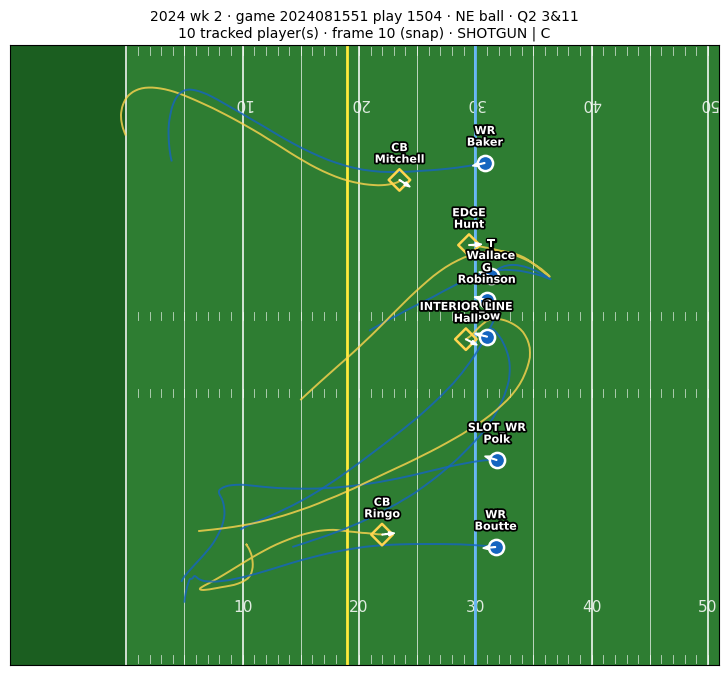

In [7]:
gid, pid = trk_pp.idxmax()
trk = load_play(gid, pid)
display(play_roster(gid, pid))
plot_play(gid, pid, trk=trk); plt.show()

In [ ]:
def plays_for(name_substring, n=5):
    m = pp[pp[NAME].astype(str).str.contains(name_substring, case=False, na=False)]
    m = m.merge(per_play[["n_players"]], left_on=["game_id", "play_id"], right_index=True)
    return m.sort_values("n_players", ascending=False)[[c for c in ["game_id", "play_id", NAME, LUP, "season", "week", "n_players"] if c]].head(n)

plays_for(str('Will Anderson').split()[-1])

Example: Roger Rosengarten


,game_id,play_id,display_name,lined_up_position,season,week,n_players
84512,2025122112,735,Will Anderson,EDGE,2025,16,9
161177,2026011801,2333,Will Anderson,INTERIOR_LINE,2025,20,8
234742,2026011801,3627,Will Anderson,EDGE,2025,20,8
221549,2026011801,1420,Will Anderson,EDGE,2025,20,8
63710,2026011801,2489,Will Anderson,EDGE,2025,20,8
